# First citywide forecasting experiment: January–February 2024

CityPulse AI forecasts urban mobility demand using Citi Bike ride starts. This is a **preliminary benchmark**, not the final modelling dataset. The final plan remains January 2024–December 2025, with training through June 2025, validation July–September 2025, and testing October–December 2025. The wider forecasting, MLOps and AI platform scope remains unchanged.

We use already validated local Parquet outputs from the January, February and March 2024 source archives. A trip belongs to the month of its **America/New_York ride start**, which may differ from its archive month. December starts are excluded; January starts from February and February starts from March are included. Original UTC timestamps and source artifacts remain unchanged.

Our target is **accepted, recorded citywide ride starts per elapsed hour**, not unconstrained demand or rejected rides. January has 31 days and February has 29: 60 × 24 = **1,440 hours**. There is no DST transition within this window.

We compare two fixed rules: yesterday's same hour (**lag 24**) and last week's same hour (**lag 168**). Neither learns parameters.

## Imports and project location
Use the **CityPulse AI (.venv)** kernel. The notebook works from the repository root or `notebooks/`; no datasets are downloaded and no cloud calls are made.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from citypulse_ai.forecasting.experiment import load_development_citywide, START, END
from citypulse_ai.forecasting.baselines import LOCAL_ZONE, evaluate_midnights

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})
ROOT

PosixPath('/Users/sanjeevani1109/Desktop/Masters/Projects/CityPulse-AI')

## Assemble and reconcile the hourly target
The reusable loader checks file hashes, source reconciliation and cross-archive ride IDs (including rejection audits). It reads compact hourly sums instead of loading trip tables into pandas. If duplicate IDs exist, it refuses to sum independently aggregated sources: a duplicate-audited catalogue is then required.

Missing citywide hours stay **unknown**; we do not silently treat them as zero. The experiment fails if labels or lag observations are missing. Zero recorded starts could be an explicit alternative assumption in a later coverage review, not a default here.

In [2]:
citywide, provenance = load_development_citywide(ROOT / "outputs/historical")
assert len(citywide) == 1440
assert provenance["missing_citywide_hours"] == 0, "Review missing hours before forecasting"
assert provenance["zero_filled_hours"] == 0
series = citywide.set_index("hour_start")["ride_count"]
monthly_counts = pd.Series(provenance["local_start_month_counts"], name="accepted_ride_starts")
display(pd.DataFrame(provenance["sources"])[["source_archive_month", "accepted_rows", "start_month_counts"]])
display(monthly_counts.to_frame())
display(pd.DataFrame({"hours": [len(series)], "accepted_starts": [int(series.sum())],
                      "missing_hours": [provenance["missing_citywide_hours"]],
                      "zero_filled_hours": [provenance["zero_filled_hours"]],
                      "cross_archive_duplicate_ids": [provenance["cross_archive_duplicate_ids"]]}))
display(citywide.head())

,source_archive_month,accepted_rows,start_month_counts
0,2024-01,1886925,"{'2023-12': 410, '2024-01': 1886515}"
1,2024-02,2119632,"{'2024-01': 231, '2024-02': 2119401}"
2,2024-03,2660499,"{'2024-02': 235, '2024-03': 2660264}"


,accepted_ride_starts
2024-01,1886746
2024-02,2119636


,hours,accepted_starts,missing_hours,zero_filled_hours,cross_archive_duplicate_ids
0,1440,4006382,0,0,0


,hour_start,ride_count,is_observed,is_zero_filled
0,2024-01-01 05:00:00+00:00,1898,True,False
1,2024-01-01 06:00:00+00:00,2329,True,False
2,2024-01-01 07:00:00+00:00,1938,True,False
3,2024-01-01 08:00:00+00:00,1098,True,False
4,2024-01-01 09:00:00+00:00,655,True,False


## Chronological development splits and forecast issuance
- **Train/reference:** January 1–31. No parameters are fitted.
- **Validation:** February 1–14 (14 midnight origins, 336 targets per baseline).
- **Test:** February 15–29 (15 midnight origins, 360 targets per baseline).

At each NYC-local midnight we predict the **next 24 elapsed hours** as one block. A midnight origin assumes the preceding hour's final count is available immediately; production reporting delays need a separate policy. For lag 24, all predictions come from the previous day's completed hours. For lag 168, they come from the corresponding hours one week earlier. Every source timestamp must be **strictly before the origin**.

This is rolling-origin evaluation: completed earlier February days become available to later forecasts. We never update predictions using observations from the day being forecast. Both lags are fixed before test evaluation; we do not tune on test results.

In [3]:
VALIDATION_START = pd.Timestamp("2024-02-01", tz=LOCAL_ZONE)
TEST_START = pd.Timestamp("2024-02-15", tz=LOCAL_ZONE)
validation_predictions, validation_metrics = evaluate_midnights(series, VALIDATION_START, TEST_START)
test_predictions, test_metrics = evaluate_midnights(series, TEST_START, END)
predictions = pd.concat([validation_predictions.assign(split="validation"),
                         test_predictions.assign(split="test")], ignore_index=True)
metrics = pd.concat([validation_metrics.assign(split="validation"),
                     test_metrics.assign(split="test")], ignore_index=True)
assert predictions.source_hour.lt(predictions.origin).all()
assert validation_predictions.hour_start.max() < TEST_START
assert test_predictions.hour_start.max() == END.tz_convert("UTC") - pd.Timedelta(hours=1)
display(predictions.head())

,origin,hour_start,source_hour,prediction,actual,lag_hours,split
0,2024-02-01 05:00:00+00:00,2024-02-01 05:00:00+00:00,2024-01-31 05:00:00+00:00,548.0,755.0,24,validation
1,2024-02-01 05:00:00+00:00,2024-02-01 06:00:00+00:00,2024-01-31 06:00:00+00:00,240.0,365.0,24,validation
2,2024-02-01 05:00:00+00:00,2024-02-01 07:00:00+00:00,2024-01-31 07:00:00+00:00,140.0,198.0,24,validation
3,2024-02-01 05:00:00+00:00,2024-02-01 08:00:00+00:00,2024-01-31 08:00:00+00:00,120.0,148.0,24,validation
4,2024-02-01 05:00:00+00:00,2024-02-01 09:00:00+00:00,2024-01-31 09:00:00+00:00,211.0,230.0,24,validation


## Error metrics
**MAE** is the mean absolute error in rides/hour. **RMSE** is also rides/hour but penalizes large errors more strongly. **WAPE** is 100 × total absolute error / total actual starts, reported as a percentage. These are pooled hourly metrics across all daily forecast blocks, not averages of daily percentages. If total actual starts were zero, WAPE would be undefined.

Validation and test are reported separately. Lower values indicate better predictions; this short experiment cannot establish performance over other seasons.

In [4]:
display(metrics[["split", "lag_hours", "forecast_origins", "target_hours", "MAE", "RMSE", "WAPE_percent"]].round(3))

,split,lag_hours,forecast_origins,target_hours,MAE,RMSE,WAPE_percent
0,validation,24,14,336,908.146,1454.002,27.897
1,validation,168,14,336,715.628,1202.430,21.983
2,test,24,15,360,759.853,1199.061,26.666
3,test,168,15,360,948.014,1438.950,33.269


## Actual versus predicted: two example weeks
Each predicted curve joins independently issued midnight forecast blocks. These plots show February 1–7 for validation and February 23–29 for test, including leap day.

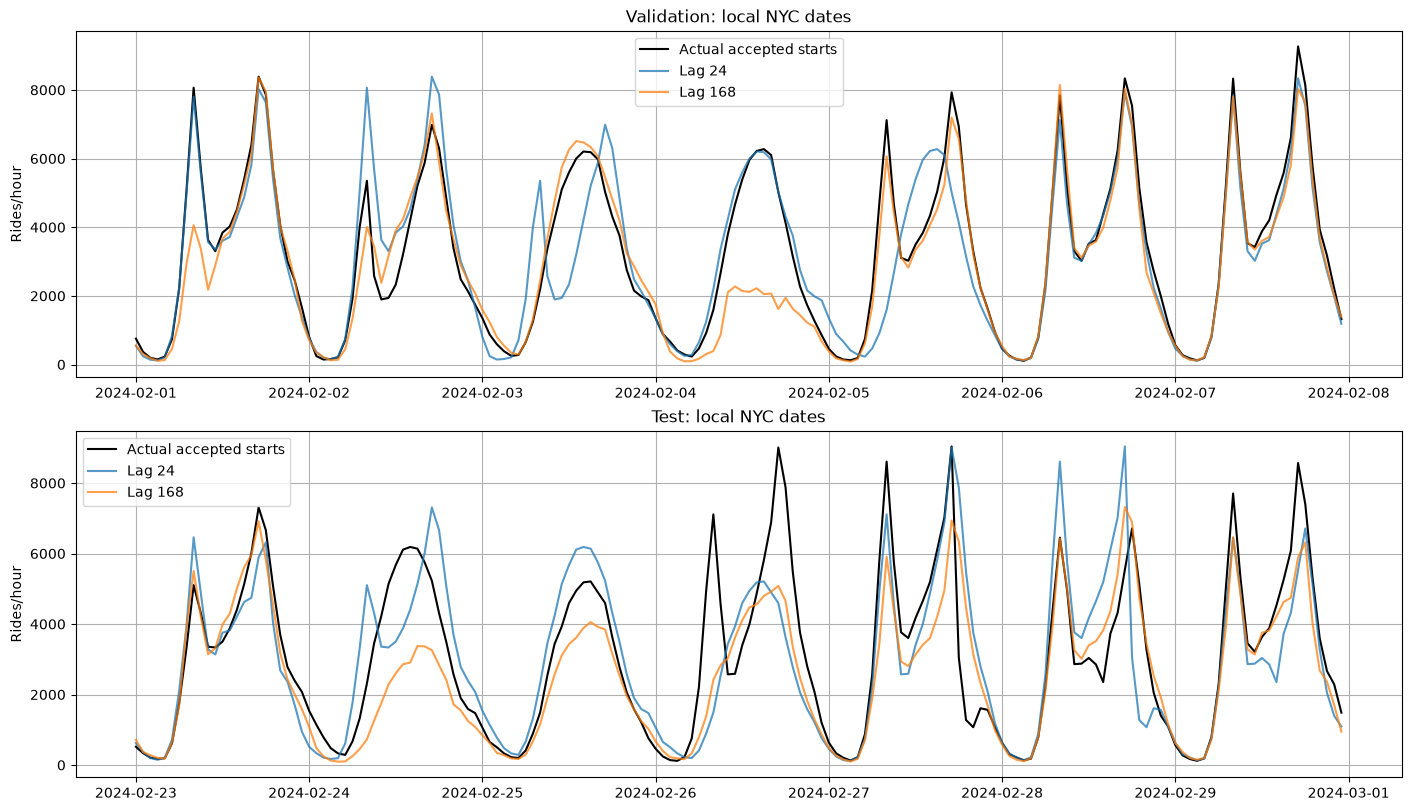

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
for ax, split, left, right in [(axes[0], "validation", "2024-02-01", "2024-02-08"),
                               (axes[1], "test", "2024-02-23", "2024-03-01")]:
    left = pd.Timestamp(left, tz=LOCAL_ZONE)
    right = pd.Timestamp(right, tz=LOCAL_ZONE)
    selected = predictions[(predictions.split == split) & (predictions.hour_start >= left) & (predictions.hour_start < right)]
    actual = selected[selected.lag_hours == 24]
    ax.plot(actual.hour_start.dt.tz_convert(LOCAL_ZONE), actual.actual, color="black", label="Actual accepted starts")
    for lag, group in selected.groupby("lag_hours"):
        ax.plot(group.hour_start.dt.tz_convert(LOCAL_ZONE), group.prediction, alpha=0.75, label=f"Lag {lag}")
    ax.set(title=f"{split.title()}: local NYC dates", ylabel="Rides/hour")
    ax.legend()
plt.show()

## Daily and weekly seasonality: inspect January only
A daily pattern means demand tends to repeat by hour of day. A weekly pattern means weekdays and weekends may behave differently. Yesterday's baseline preserves yesterday's shape but can confuse a weekday with a weekend. Last week's baseline preserves weekday alignment but uses older observations.

These descriptive plots use January reference data only. Four or five examples per weekday are limited evidence; weather, holidays and system changes may outweigh either seasonal rule.

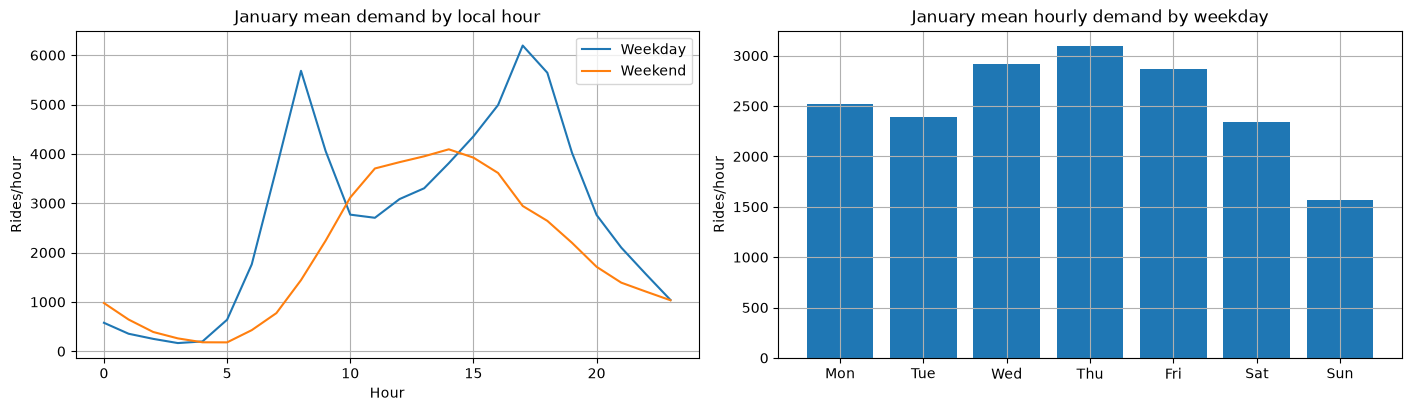

In [6]:
reference = series[series.index < VALIDATION_START]
local = reference.index.tz_convert(LOCAL_ZONE)
profile = pd.DataFrame({"rides": reference.to_numpy(dtype=float), "hour": local.hour,
                        "weekday": local.dayofweek, "weekend": local.dayofweek >= 5})
fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
for weekend, group in profile.groupby("weekend"):
    hourly_profile = group.groupby("hour").rides.mean()
    axes[0].plot(hourly_profile.index, hourly_profile, label="Weekend" if weekend else "Weekday")
axes[0].set(title="January mean demand by local hour", xlabel="Hour", ylabel="Rides/hour")
axes[0].legend()
weekly_profile = profile.groupby("weekday").rides.mean()
axes[1].bar(range(7), weekly_profile.reindex(range(7)))
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set(title="January mean hourly demand by weekday", ylabel="Rides/hour")
plt.show()

## What the measured comparison tells us
The next cell summarizes the measured results without claiming general superiority. A low aggregate error can still hide peak-hour failures. The observed daily/weekly profiles suggest useful baselines, not a causal explanation of demand.

In [7]:
for split, group in metrics.groupby("split", sort=False):
    daily = group[group.lag_hours == 24].iloc[0]
    weekly = group[group.lag_hours == 168].iloc[0]
    display(Markdown(f"**{split.title()}**: lag 24 MAE = {daily.MAE:.2f}, WAPE = {daily.WAPE_percent:.2f}%; "
                     f"lag 168 MAE = {weekly.MAE:.2f}, WAPE = {weekly.WAPE_percent:.2f}%. "
                     "Compare this table and the peak-hour plots before drawing conclusions."))

**Validation**: lag 24 MAE = 908.15, WAPE = 27.90%; lag 168 MAE = 715.63, WAPE = 21.98%. Compare this table and the peak-hour plots before drawing conclusions.

**Test**: lag 24 MAE = 759.85, WAPE = 26.67%; lag 168 MAE = 948.01, WAPE = 33.27%. Compare this table and the peak-hour plots before drawing conclusions.

## Limitations and next steps
- January–February is a winter-only, two-month sample. Fifteen test origins provide limited evidence and correlated hourly errors; we make no statistical significance claim.
- Counts exclude rejected rides and reflect the recorded system, not unmet demand. Adjacent archives were checked, but archive completeness and vendor corrections remain assumptions.
- No station-level model, weather integration, learned model or final 24-month evaluation is implemented here.
- Zero reporting latency is assumed at midnight. Future experiments must address ingestion delay and DST: 24 elapsed hours need not equal a local calendar day.
- Continue the fixed 24-month ingestion plan, then evaluate the same baselines over the final chronological splits before introducing ARIMA, XGBoost or neural networks. Select the 100-station cohort using training data only.

The executed outputs above are the results of this preliminary experiment. Re-running uses existing local artifacts; no cloud access or raw ETL is needed.